# Previsao da Area 1 - split temporal, sem clima


In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

RANDOM_STATE = 42
ALPHA = 0.05
FREQUENCIA_MINIMA = 5
N_SPLITS_CV = 3
COLUNAS_CLIMA = [
    "Precipitacao_mm", "Temp_max_C", "Temp_min_C",
    "Umid_rel_ar", "Vento_velocidade_ms", "Vento_rajada_maxima_ms",
]

candidatos_csv = [
    Path("../data/dataarea1.csv"),
    Path("previsao/data/dataarea1.csv"),
    Path("../../previsao/data/dataarea1.csv"),
    Path("data/dataarea1.csv"),
]
CSV_PATH = next((caminho.resolve() for caminho in candidatos_csv if caminho.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError(
        "Nao encontrei dataarea1.csv. Execute o notebook a partir da pasta do projeto "
        "ou de previsao/notebooks."
    )

print(f"Arquivo utilizado: {CSV_PATH}")

Arquivo utilizado: C:\Users\lucas\Documents\USP\Python\projeto-ru\previsao\data\dataarea1.csv


## Carregamento e limpeza


In [10]:
data = pd.read_csv(CSV_PATH, encoding="cp1252")

# Identifica nomes acentuados sem depender da codificacao do arquivo do notebook.
COLUNA_MES = next(coluna for coluna in data.columns if coluna.startswith("M"))
COLUNA_DIA_MES = next(coluna for coluna in data.columns if coluna.startswith("Dia_m"))
COLUNA_GUARNICAO = next(coluna for coluna in data.columns if coluna.startswith("guarni"))

# A previsao final nao utiliza dados meteorologicos.
data = data.drop(columns=COLUNAS_CLIMA, errors="ignore")
data = data.loc[data["refeicao"] != "cafe da manha"].copy()
data = data.dropna().copy()
data = data.loc[data["total"] != 0].copy()

data["_data_split"] = pd.to_datetime(
    {
        "year": data["Ano"],
        "month": data[COLUNA_MES],
        "day": data[COLUNA_DIA_MES],
    },
    errors="coerce",
)
if data["_data_split"].isna().any():
    raise ValueError("Existem datas invalidas em Ano, Mes ou Dia_mes.")

data["_semestre"] = np.where(data[COLUNA_MES] <= 6, 1, 2)
data = data.sort_values("_data_split", kind="stable").reset_index(drop=True)

COLUNAS_CATEGORICAS = [
    COLUNA_MES, "Dia_semana", COLUNA_DIA_MES, "prato_principal_1",
    "prato_principal_2", COLUNA_GUARNICAO, "sobremesa_1", "refeicao",
]
COLUNAS_FILTRO_RARO = [
    COLUNA_GUARNICAO, "prato_principal_1", "prato_principal_2", "sobremesa_1"
]

print(f"Observacoes apos limpeza basica: {len(data)}")
print("Observacoes por ano:")
display(data.groupby("Ano").size().rename("observacoes").to_frame())
print("Colunas climaticas no CSV:", [coluna for coluna in COLUNAS_CLIMA if coluna in data.columns])

Observacoes apos limpeza basica: 1512
Observacoes por ano:


,observacoes
Ano,
2023,507
2024,516
2025,489


Colunas climaticas no CSV: []


## Divisao temporal


In [11]:
mascara_treino = (data["Ano"] == 2023) | (
    (data["Ano"] == 2024) & (data[COLUNA_MES] <= 6)
)
mascara_calibracao = (data["Ano"] == 2024) & (data[COLUNA_MES] >= 7)
mascara_teste = data["Ano"] == 2025

if not mascara_treino.any() or not mascara_calibracao.any() or not mascara_teste.any():
    raise ValueError("Uma das particoes temporais ficou vazia.")

assert data.loc[mascara_treino, "_data_split"].max() < data.loc[mascara_calibracao, "_data_split"].min()
assert data.loc[mascara_calibracao, "_data_split"].max() < data.loc[mascara_teste, "_data_split"].min()

resumo_particoes = pd.DataFrame(
    {
        "particao": ["Treino", "Calibracao", "Teste"],
        "periodo": ["jan/2023 a jun/2024", "jul/2024 a dez/2024", "jan/2025 a dez/2025"],
        "datas_distintas": [
            data.loc[mascara_treino, "_data_split"].nunique(),
            data.loc[mascara_calibracao, "_data_split"].nunique(),
            data.loc[mascara_teste, "_data_split"].nunique(),
        ],
        "observacoes": [int(mascara_treino.sum()), int(mascara_calibracao.sum()), int(mascara_teste.sum())],
    }
)
display(resumo_particoes)

,particao,periodo,datas_distintas,observacoes
0,Treino,jan/2023 a jun/2024,419,772
1,Calibracao,jul/2024 a dez/2024,136,251
2,Teste,jan/2025 a dez/2025,266,489


## Comparacao temporal, ajuste do ensemble e calibracao conformal


In [12]:
def filtrar_categorias_raras(dados_treino):
    dados_filtrados = dados_treino.copy()
    for coluna in COLUNAS_FILTRO_RARO:
        frequencias = dados_filtrados[coluna].value_counts()
        dados_filtrados = dados_filtrados.loc[
            dados_filtrados[coluna].map(frequencias).ge(FREQUENCIA_MINIMA)
        ].copy()
    return dados_filtrados


def preparar_features(dados_treino, *particoes):
    dados_treino_filtrado = filtrar_categorias_raras(dados_treino)
    colunas_excluir = ["total", "Ano", "_data_split", "_semestre"]
    X_treino = pd.get_dummies(
        dados_treino_filtrado.drop(columns=colunas_excluir),
        columns=COLUNAS_CATEGORICAS,
        dtype=int,
    )

    matrizes = [X_treino]
    for dados_validacao in particoes:
        X_validacao = pd.get_dummies(
            dados_validacao.drop(columns=colunas_excluir),
            columns=COLUNAS_CATEGORICAS,
            dtype=int,
        ).reindex(columns=X_treino.columns, fill_value=0)
        matrizes.append(X_validacao)
    return (dados_treino_filtrado, *matrizes)


modelos_comparacao = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1,
    ),
}

dados_treino_cv = data.loc[mascara_treino]
datas_treino_cv = np.sort(dados_treino_cv["_data_split"].unique())
predicoes_cv = {nome: {"real": [], "previsto": []} for nome in modelos_comparacao}
cv_temporal = TimeSeriesSplit(n_splits=N_SPLITS_CV)

for numero_fold, (indices_ajuste, indices_validacao) in enumerate(cv_temporal.split(datas_treino_cv), start=1):
    datas_ajuste = datas_treino_cv[indices_ajuste]
    datas_validacao = datas_treino_cv[indices_validacao]
    dados_ajuste = dados_treino_cv.loc[dados_treino_cv["_data_split"].isin(datas_ajuste)]
    dados_validacao = dados_treino_cv.loc[dados_treino_cv["_data_split"].isin(datas_validacao)]
    dados_ajuste_filtrado, X_ajuste, X_validacao = preparar_features(dados_ajuste, dados_validacao)
    y_ajuste = dados_ajuste_filtrado["total"].astype(float)
    y_validacao = dados_validacao["total"].astype(float)

    for nome, estimador in modelos_comparacao.items():
        modelo_fold = clone(estimador)
        modelo_fold.fit(X_ajuste, y_ajuste)
        previsoes_fold = modelo_fold.predict(X_validacao)
        predicoes_cv[nome]["real"].extend(y_validacao.to_numpy())
        predicoes_cv[nome]["previsto"].extend(previsoes_fold)
    print(f"Fold {numero_fold}: ajuste ate {pd.Timestamp(datas_ajuste[-1]):%d/%m/%Y}; validacao ate {pd.Timestamp(datas_validacao[-1]):%d/%m/%Y}")

resultados_cv = []
for nome, valores in predicoes_cv.items():
    y_real_cv = np.asarray(valores["real"])
    y_previsto_cv = np.asarray(valores["previsto"])
    resultados_cv.append(
        {
            "Modelo": nome,
            "MAE": mean_absolute_error(y_real_cv, y_previsto_cv),
            "RMSE": np.sqrt(mean_squared_error(y_real_cv, y_previsto_cv)),
            "R2": r2_score(y_real_cv, y_previsto_cv),
        }
    )
display(pd.DataFrame(resultados_cv).sort_values("MAE").round(3))

# Ajusta o ensemble final somente no periodo de treino; calibracao e teste ficam intocados.
dados_treino_filtrado, X_treino, X_calibracao, X_teste = preparar_features(
    data.loc[mascara_treino], data.loc[mascara_calibracao], data.loc[mascara_teste]
)
y_treino = dados_treino_filtrado["total"].astype(float)
y_calibracao = data.loc[mascara_calibracao, "total"].astype(float)
y_teste = data.loc[mascara_teste, "total"].astype(float)

modelo = VotingRegressor(
    estimators=[
        ("gb", GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_STATE)),
        ("rf", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    ],
    weights=[3, 1],
)
modelo.fit(X_treino, y_treino)

previsoes_calibracao = np.maximum(modelo.predict(X_calibracao), 0)
residuos_calibracao_assinados = y_calibracao.to_numpy() - previsoes_calibracao
residuos_calibracao = np.abs(residuos_calibracao_assinados)


def identificar_dias_transicao(dados):
    """Marca os 10 primeiros e os 10 ultimos dias letivos de cada semestre civil."""
    datas_transicao = set()
    dias_letivos = dados.loc[dados["letivo"] == 1]
    for _, grupo in dias_letivos.groupby(["Ano", "_semestre"]):
        datas = grupo["_data_split"].drop_duplicates().sort_values()
        datas_transicao.update(datas.head(10).tolist())
        datas_transicao.update(datas.tail(10).tolist())
    return dados["_data_split"].isin(datas_transicao).to_numpy()


def quantil_conformal(residuos, alpha=ALPHA):
    residuos_ordenados = np.sort(np.asarray(residuos, dtype=float))
    if len(residuos_ordenados) == 0:
        raise ValueError("Nao ha residuos disponiveis para calibrar a margem conformal.")
    ordem = int(np.ceil((len(residuos_ordenados) + 1) * (1 - alpha)))
    if ordem > len(residuos_ordenados):
        return float("inf")
    return float(residuos_ordenados[ordem - 1])


mascara_transicao_calibracao = identificar_dias_transicao(data.loc[mascara_calibracao])
MIN_AMOSTRAS_MARGEM_ESPECIFICA = int(np.ceil(1 / ALPHA) - 1)
# Para dias regulares, usa-se o quantil geral de calibracao reportado no artigo.
margem_conformal_geral = float(np.quantile(residuos_calibracao, 1 - ALPHA, method="higher"))
residuos_transicao = residuos_calibracao[mascara_transicao_calibracao]
margem_conformal_regular = margem_conformal_geral
margem_conformal_transicao = (
    quantil_conformal(residuos_transicao)
    if len(residuos_transicao) >= MIN_AMOSTRAS_MARGEM_ESPECIFICA
    else margem_conformal_geral
)

print(f"Treino apos filtro de categorias: {len(y_treino)} observacoes")
print(f"Calibracao: {len(y_calibracao)} observacoes ({len(residuos_transicao)} de transicao; {len(y_calibracao) - len(residuos_transicao)} regulares)")
print(f"Nivel nominal: {(1 - ALPHA):.0%}")
print(f"Margem geral: +/- {margem_conformal_geral:.1f}")
print(f"Margem dias regulares: +/- {margem_conformal_regular:.1f}")
print(f"Margem dias de transicao: +/- {margem_conformal_transicao:.1f}")

Fold 1: ajuste ate 17/05/2023; validacao ate 26/09/2023
Fold 2: ajuste ate 26/09/2023; validacao ate 22/02/2024
Fold 3: ajuste ate 22/02/2024; validacao ate 29/06/2024


,Modelo,MAE,RMSE,R2
3,XGBoost,229.008,305.224,0.847
2,Gradient Boosting,230.441,299.990,0.852
1,Random Forest,237.477,313.895,0.838
0,Ridge,288.874,377.137,0.766


Treino apos filtro de categorias: 690 observacoes
Calibracao: 251 observacoes (36 de transicao; 215 regulares)
Nivel nominal: 95%
Margem geral: +/- 469.7
Margem dias regulares: +/- 469.7
Margem dias de transicao: +/- 799.0


## Avaliacao final em 2025


In [13]:
previsoes_teste = np.maximum(modelo.predict(X_teste), 0)
residuos_teste_assinados = y_teste.to_numpy() - previsoes_teste
residuos_teste = np.abs(residuos_teste_assinados)
mascara_transicao_teste = identificar_dias_transicao(data.loc[mascara_teste])
margens_teste = np.where(
    mascara_transicao_teste,
    margem_conformal_transicao,
    margem_conformal_regular,
)
limite_inferior = np.maximum(0, previsoes_teste - margens_teste)
limite_superior = previsoes_teste + margens_teste


def calcular_metricas(y_real, y_previsto, inferior, superior):
    return {
        "Observacoes": len(y_real),
        "MAE": mean_absolute_error(y_real, y_previsto),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_previsto)),
        "R2": r2_score(y_real, y_previsto),
        "Residuo medio (real - previsto)": float(np.mean(y_real - y_previsto)),
        "Margem media": float(np.mean((superior - inferior) / 2)),
        "Cobertura": float(np.mean((y_real >= inferior) & (y_real <= superior))),
    }


linhas_metricas = [
    {"Grupo": "Geral", **calcular_metricas(y_teste.to_numpy(), previsoes_teste, limite_inferior, limite_superior)},
]
for nome_grupo, mascara_grupo, margem in [
    ("Dias regulares", ~mascara_transicao_teste, margem_conformal_regular),
    ("Dias de transicao", mascara_transicao_teste, margem_conformal_transicao),
]:
    if mascara_grupo.any():
        y_grupo = y_teste.to_numpy()[mascara_grupo]
        previsoes_grupo = previsoes_teste[mascara_grupo]
        inferior_grupo = limite_inferior[mascara_grupo]
        superior_grupo = limite_superior[mascara_grupo]
        linhas_metricas.append(
            {"Grupo": nome_grupo, **calcular_metricas(y_grupo, previsoes_grupo, inferior_grupo, superior_grupo)}
        )

metricas_teste = pd.DataFrame(linhas_metricas)
display(metricas_teste.round(3))

resultado_teste = pd.DataFrame(
    {
        "Data": data.loc[mascara_teste, "_data_split"].to_numpy(),
        "Refeicao": data.loc[mascara_teste, "refeicao"].to_numpy(),
        "Real": y_teste.to_numpy(),
        "Previsto": previsoes_teste,
        "Margem conformal": margens_teste,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Erro absoluto": residuos_teste,
    }
)
amostra_resultado = resultado_teste.head(10).copy()
colunas_numericas = amostra_resultado.select_dtypes(include="number").columns
amostra_resultado[colunas_numericas] = amostra_resultado[colunas_numericas].round(1)
display(amostra_resultado)

,Grupo,Observacoes,MAE,RMSE,R2,Residuo medio (real - previsto),Margem media,Cobertura
0,Geral,489,162.091,211.319,0.934,-3.113,520.829,0.973
1,Dias regulares,413,151.978,200.633,0.945,-9.428,469.634,0.969
2,Dias de transicao,76,217.044,261.871,0.724,31.204,799.030,1.000


,Data,Refeicao,Real,Previsto,Margem conformal,Limite inferior,Limite superior,Erro absoluto
0,2025-01-06,almoco,401.0,792.8,469.7,323.1,1262.5,391.8
1,2025-01-06,jantar,324.0,619.1,469.7,149.5,1088.8,295.1
2,2025-01-07,almoco,464.0,670.8,469.7,201.1,1140.5,206.8
3,2025-01-07,jantar,440.0,663.6,469.7,193.9,1133.3,223.6
4,2025-01-08,almoco,470.0,742.5,469.7,272.8,1212.2,272.5
5,2025-01-08,jantar,384.0,518.6,469.7,48.9,988.3,134.6
6,2025-01-09,almoco,546.0,775.0,469.7,305.3,1244.7,229.0
7,2025-01-09,jantar,441.0,605.3,469.7,135.6,1075.0,164.3
8,2025-01-10,almoco,517.0,772.2,469.7,302.5,1241.8,255.2
9,2025-01-10,jantar,358.0,491.0,469.7,21.4,960.7,133.0


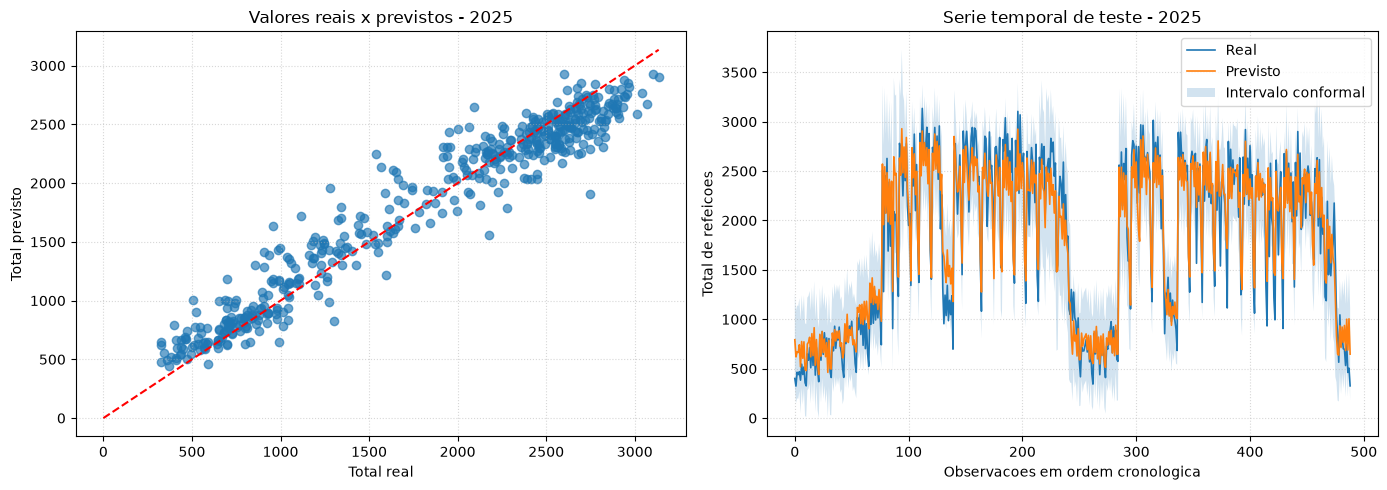

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_teste, previsoes_teste, alpha=0.65)
limite = max(float(y_teste.max()), float(previsoes_teste.max()))
axes[0].plot([0, limite], [0, limite], color="red", linestyle="--")
axes[0].set_title("Valores reais x previstos - 2025")
axes[0].set_xlabel("Total real")
axes[0].set_ylabel("Total previsto")
axes[0].grid(True, linestyle=":", alpha=0.5)

indices = np.arange(len(y_teste))
axes[1].plot(indices, y_teste.to_numpy(), label="Real", linewidth=1.2)
axes[1].plot(indices, previsoes_teste, label="Previsto", linewidth=1.2)
axes[1].fill_between(indices, limite_inferior, limite_superior, alpha=0.2, label="Intervalo conformal")
axes[1].set_title("Serie temporal de teste - 2025")
axes[1].set_xlabel("Observacoes em ordem cronologica")
axes[1].set_ylabel("Total de refeicoes")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()